# Track 2: Financial Fraud Detection

Predict whether a transaction is fraud (`fraud` = 1). Only ~1.8% of transactions are fraud, so this is a very imbalanced problem.
Metrics: **PR-AUC** (needs probabilities), **F1** and **Recall** (need a 0/1 label, so a threshold).

**Outline**
1. Load data
2. Why accuracy is useless here
3. EDA
4. Features and preprocessing
5. Validation and models
6. Threshold tuning
7. Error analysis
8. Train on all data, predict test, save files

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloudpickle
from pathlib import Path

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, recall_score,
                             precision_score, precision_recall_curve, confusion_matrix)

SEED = 42
N_JOBS = 4  # shared machine, don't use every core

# Folder with the two csv files. On Colab, upload them next to the notebook.
DATA_DIR = Path("../Track 2 Dataset")
if not DATA_DIR.exists():
    DATA_DIR = Path(".")

plt.rcParams["figure.dpi"] = 100

## 1. Load data

In [2]:
train = pd.read_csv(DATA_DIR / "Track 2 Training Dataset.csv")
test = pd.read_csv(DATA_DIR / "Track 2 Testing Dataset.csv")
LABEL = "fraud"

print("train:", train.shape, " test:", test.shape)
print("columns only in train:", set(train.columns) - set(test.columns))
train.head()

train: (20000, 12)  test: (12000, 11)
columns only in train: {'fraud'}


,id,transaction_amount,transaction_hour,merchant_category,country,transaction_channel,transactions_last_24h,spend_last_24h,account_age,new_device,transactions_last_1h,fraud
0,FR016993,55.03,16,retail,SG,ecommerce,27.0,1791.34,1192.0,0.0,5.0,0
1,FR002433,20.75,1,gaming,SG,mobile_app,3.0,217.96,3073.0,0.0,0.0,0
2,FR009253,21.51,9,entertainment,SG,mobile_app,3.0,62.71,985.0,0.0,0.0,0
3,FR004881,813.98,16,utilities,GB,mobile_app,2.0,110.48,653.0,0.0,1.0,0
4,FR014830,13.54,20,food_delivery,SG,card_present,4.0,114.98,79.0,0.0,0.0,0


In [3]:
n_fraud = train[LABEL].sum()
n_legit = (train[LABEL] == 0).sum()
print(f"fraud: {n_fraud} ({100 * n_fraud / len(train):.2f}%)  legit: {n_legit}")
print(f"fraud : legit = 1 : {n_legit / n_fraud:.1f}")

fraud: 353 (1.76%)  legit: 19647
fraud : legit = 1 : 55.7


In [4]:
missing = pd.DataFrame({
    "train_%": train.isna().mean() * 100,
    "test_%": test.isna().mean() * 100,
}).round(2)
display(missing[missing.sum(axis=1) > 0])

print("duplicate ids:", train["id"].duplicated().sum())
print("duplicate rows (ignoring id):", train.drop(columns="id").duplicated().sum())
print(train.nunique().sort_values())

,train_%,test_%
account_age,0.68,2.20
country,0.53,2.23
merchant_category,0.56,2.16
new_device,0.62,2.44
spend_last_24h,0.66,2.22
transaction_channel,0.62,2.37
transactions_last_1h,0.71,2.04
transactions_last_24h,0.80,2.44


duplicate ids: 0
duplicate rows (ignoring id): 0
fraud                        2
new_device                   2
transaction_channel          4
country                     10
transactions_last_1h        10
merchant_category           11
transaction_hour            24
transactions_last_24h       27
account_age               3366
transaction_amount       14134
spend_last_24h           16987
id                       20000
dtype: int64


In [5]:
train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
transaction_amount,20000.0,252.66,603.84,2.5,31.83,75.12,205.2,9000.00
transaction_hour,20000.0,11.45,6.89,0.0,5.00,11.00,17.0,23.00
transactions_last_24h,19841.0,4.64,2.63,1.0,3.00,4.00,6.0,27.00
spend_last_24h,19868.0,555.26,962.35,0.0,93.84,217.52,576.0,15670.31
account_age,19863.0,1053.65,963.53,5.0,342.00,790.00,1483.0,4000.00
new_device,19876.0,0.09,0.29,0.0,0.00,0.00,0.0,1.00
transactions_last_1h,19858.0,0.87,1.10,0.0,0.00,1.00,1.0,9.00
fraud,20000.0,0.02,0.13,0.0,0.00,0.00,0.0,1.00


**Notes**
- 20,000 train rows, 12,000 test rows, 353 frauds (1.77%).
- Small amounts of missing data everywhere (~0.7% in train, ~2.3% in test), no duplicates.
- No timestamp other than the hour, so we use stratified K-fold.

## 2. Why accuracy is useless here

In [6]:
always_legit = np.zeros(len(train))
print("Predict 'not fraud' for everything:")
print("  accuracy:", round(accuracy_score(train[LABEL], always_legit), 4))
print("  recall:  ", recall_score(train[LABEL], always_legit))
print("  F1:      ", f1_score(train[LABEL], always_legit))

Predict 'not fraud' for everything:
  accuracy: 0.9823
  recall:   0.0
  F1:       0.0


This useless model gets 98.2% accuracy and catches zero fraud. So from here on we only look at PR-AUC, F1, recall and precision.

## 3. EDA

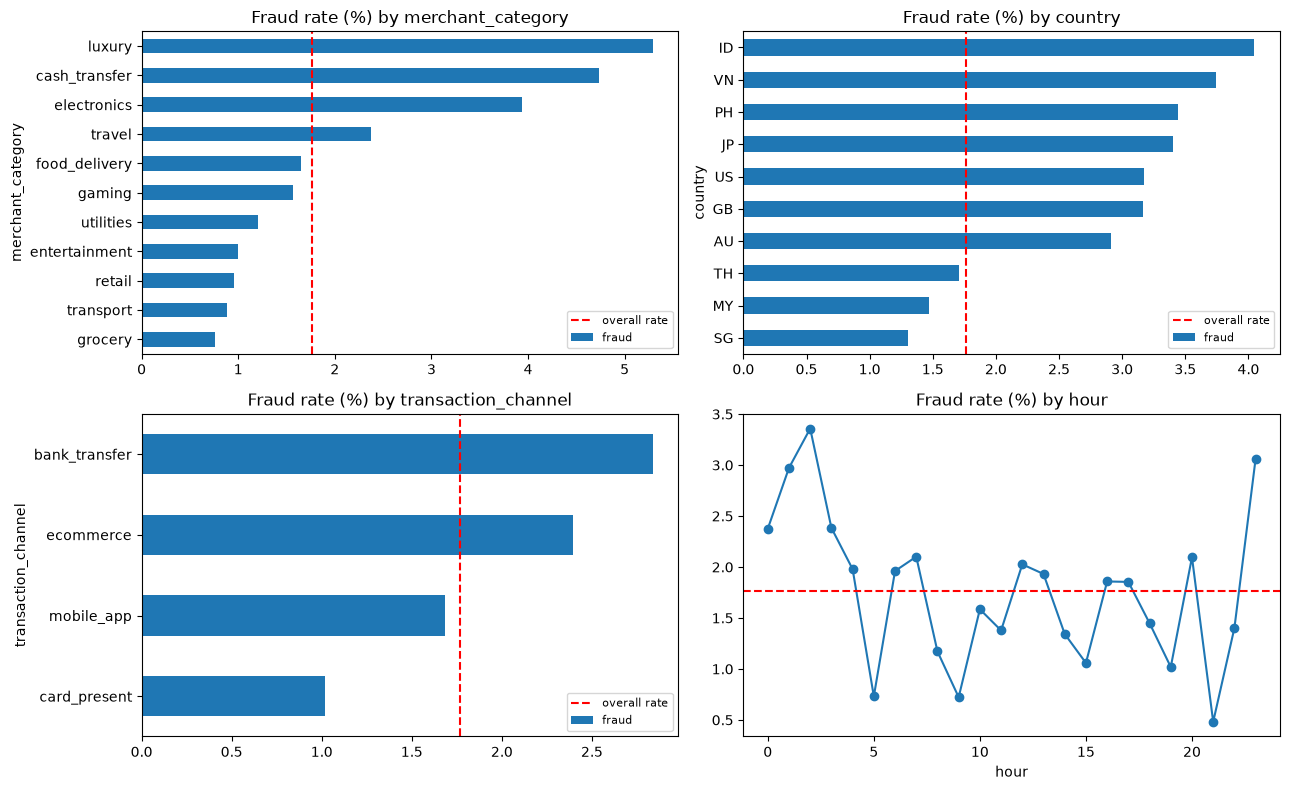

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
base_rate = train[LABEL].mean()

for ax, col in zip(axes.flat[:3], ["merchant_category", "country", "transaction_channel"]):
    rate = train.groupby(col)[LABEL].mean().sort_values() * 100
    rate.plot.barh(ax=ax)
    ax.axvline(base_rate * 100, color="red", linestyle="--", label="overall rate")
    ax.set_title(f"Fraud rate (%) by {col}")
    ax.legend(fontsize=8)

(train.groupby("transaction_hour")[LABEL].mean() * 100).plot(marker="o", ax=axes[1, 1])
axes[1, 1].axhline(base_rate * 100, color="red", linestyle="--")
axes[1, 1].set_title("Fraud rate (%) by hour")
axes[1, 1].set_xlabel("hour")

plt.tight_layout()
plt.show()

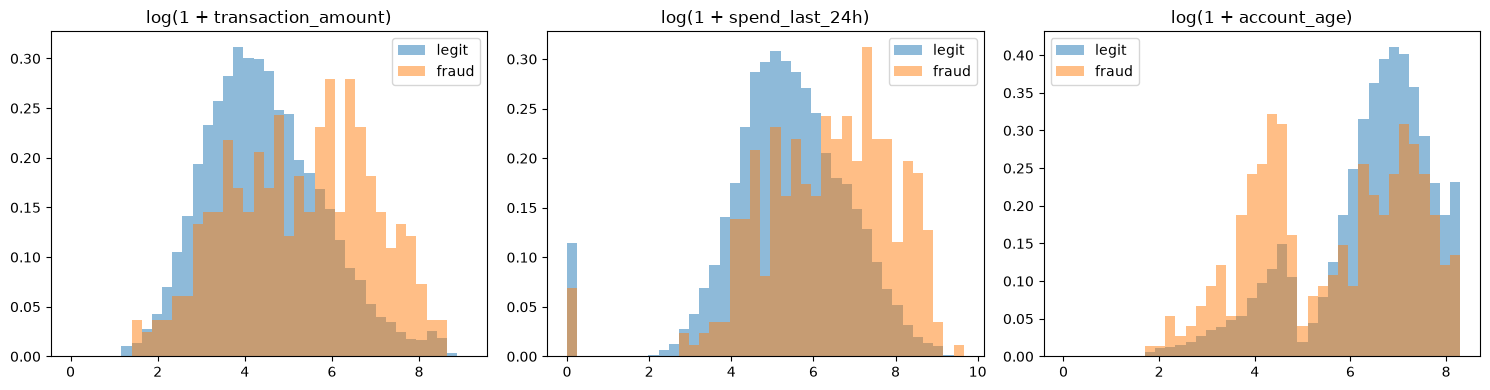

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["transaction_amount", "spend_last_24h", "account_age"]):
    bins = np.linspace(0, np.log1p(train[col].max()), 40)
    for label, name in [(0, "legit"), (1, "fraud")]:
        vals = np.log1p(train.loc[train[LABEL] == label, col].dropna())
        ax.hist(vals, bins=bins, density=True, alpha=0.5, label=name)
    ax.set_title(f"log(1 + {col})")
    ax.legend()
plt.tight_layout()
plt.show()

In [9]:
compare_cols = ["transaction_amount", "spend_last_24h", "account_age", "transactions_last_24h",
                "transactions_last_1h", "new_device"]
train.groupby(LABEL)[compare_cols].agg(["median", "mean"]).T.round(2)

fraud                               0        1
transaction_amount    median    74.26   224.26
                      mean     246.95   570.81
spend_last_24h        median   214.51   662.82
                      mean     539.25  1451.02
account_age           median   796.00   335.50
                      mean    1059.20   744.17
transactions_last_24h median     4.00     5.00
                      mean       4.59     7.61
transactions_last_1h  median     1.00     1.00
                      mean       0.85     1.91
new_device            median     0.00     0.00
                      mean       0.09     0.38

**EDA findings**
- **Amount** is the clearest signal: median fraud amount is ~3× the legit one.
- **Merchant category:** luxury, cash transfer and electronics have 2–3× the base fraud rate. Grocery and transport are the safest.
- **Country:** transactions outside Singapore are 2–3× riskier than domestic ones.
- **Channel:** bank transfer and e-commerce are riskier than card-present.
- **Hour:** a higher fraud rate late at night (around 23h–3h).
- **Customer behaviour:** fraud accounts are younger (median 336 vs 796 days), use a new device far more often (38% vs 9%), and make more transactions in the last hour and day.
- Amount, spend and account age are very right-skewed, so we log them for the linear model.

## 4. Features and preprocessing

A few simple features from the EDA:
- `log_amount`, `log_spend_24h`, `log_account_age`: handle the skew
- `amount_vs_avg`: this transaction vs the customer's average transaction in the last 24h (big jump = suspicious)
- `is_night`: hour in 23–3
- `is_foreign`: country is not SG

The feature function sits inside the pipeline (`FunctionTransformer`), so the saved model runs on the raw test csv.

In [10]:
CAT_COLS = ["merchant_category", "country", "transaction_channel"]


def add_features(df):
    df = df.copy()
    avg_txn = df["spend_last_24h"] / df["transactions_last_24h"].replace(0, np.nan)
    df["amount_vs_avg"] = np.log1p(df["transaction_amount"] / (avg_txn + 1))
    df["log_amount"] = np.log1p(df["transaction_amount"])
    df["log_spend_24h"] = np.log1p(df["spend_last_24h"])
    df["log_account_age"] = np.log1p(df["account_age"])
    df["is_night"] = df["transaction_hour"].isin([23, 0, 1, 2, 3]).astype(int)
    df["is_foreign"] = (df["country"].notna() & (df["country"] != "SG")).astype(int)
    # raw versions are replaced by the log versions
    return df.drop(columns=["id", "transaction_amount", "spend_last_24h", "account_age"], errors="ignore")


X = train.drop(columns=[LABEL])
y = train[LABEL]
NUM_COLS = [c for c in add_features(X.head()).columns if c not in CAT_COLS]
print("numeric features:", NUM_COLS)

numeric features: ['transaction_hour', 'transactions_last_24h', 'new_device', 'transactions_last_1h', 'amount_vs_avg', 'log_amount', 'log_spend_24h', 'log_account_age', 'is_night', 'is_foreign']


In [11]:
def make_logreg(C=1.0, class_weight=None):
    prep = ColumnTransformer([
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                              OneHotEncoder(handle_unknown="ignore")), CAT_COLS),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_COLS),
    ])
    return make_pipeline(FunctionTransformer(add_features), prep,
                         LogisticRegression(C=C, class_weight=class_weight, max_iter=3000))


def make_forest():
    prep = ColumnTransformer([
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                              OneHotEncoder(handle_unknown="ignore")), CAT_COLS),
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
    ])
    model = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample",
                                   n_jobs=N_JOBS, random_state=SEED)
    return make_pipeline(FunctionTransformer(add_features), prep, model)


def make_hgb():
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                               encoded_missing_value=-2), CAT_COLS),
        ("num", "passthrough", NUM_COLS),
    ])
    # shallow trees + strong regularisation: with only 353 frauds deep trees overfit
    model = HistGradientBoostingClassifier(categorical_features=[0, 1, 2], learning_rate=0.05, max_iter=300,
                                           max_depth=3, min_samples_leaf=40, l2_regularization=1.0,
                                           early_stopping=False, random_state=SEED)
    return make_pipeline(FunctionTransformer(add_features), prep, model)

## 5. Validation and models

Stratified 5-fold, so every fold has ~70 frauds. For each model we collect **out-of-fold probabilities** and compute:
- **PR-AUC** (average precision), which doesn't depend on a threshold
- **best F1** over all thresholds, plus the recall at that threshold

We also show the PR-AUC spread across folds. With only ~70 frauds per fold, small differences between models are noise.

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def run_cv(make_model):
    oof = np.zeros(len(X))
    fold_ap = []
    for tr_idx, va_idx in skf.split(X, y):
        model = make_model().fit(X.iloc[tr_idx], y.iloc[tr_idx])
        oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]
        fold_ap.append(average_precision_score(y.iloc[va_idx], oof[va_idx]))
    return oof, np.array(fold_ap)


def best_f1(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    i = f1[:-1].argmax()  # last point has no threshold
    return f1[i], thresholds[i], recall[i], precision[i]


results = []
oof_probs = {}


def record(name, make_model):
    oof, fold_ap = run_cv(make_model)
    f1, thr, rec, prec = best_f1(y, oof)
    oof_probs[name] = oof
    results.append({"model": name, "PR-AUC": average_precision_score(y, oof), "PR-AUC fold std": fold_ap.std(),
                    "best F1": f1, "recall @ best F1": rec, "precision @ best F1": prec})


record("Dummy (fraud rate)", lambda: DummyClassifier(strategy="prior"))
record("LogReg balanced", lambda: make_logreg(class_weight="balanced"))
record("LogReg", lambda: make_logreg())
record("Random forest balanced", make_forest)
record("HistGradientBoosting", make_hgb)

pd.DataFrame(results).set_index("model").round(4)

,PR-AUC,PR-AUC fold std,best F1,recall @ best F1,precision @ best F1
model,,,,,
Dummy (fraud rate),0.0176,0.0001,0.0347,1.0000,0.0176
LogReg balanced,0.2138,0.0222,0.2768,0.2011,0.4438
LogReg,0.2286,0.0177,0.2857,0.2578,0.3204
Random forest balanced,0.1875,0.0363,0.2723,0.1813,0.5470
HistGradientBoosting,0.1806,0.0294,0.2687,0.2295,0.3240


The dummy model's PR-AUC equals the fraud rate (0.018), which is the "random" level for PR-AUC.

**Logistic regression with the log features does as well as or better than the tree models.** The signal here is mostly additive: a big amount *plus* a risky category *plus* a foreign country each add risk. Trees don't find anything extra and are noisier with so few frauds.

**Class weights:** `class_weight="balanced"` did *not* help PR-AUC. Weighting only shifts the probabilities up. It doesn't rank fraud better, and we pick the threshold ourselves in step 6 anyway. So we keep the unweighted model, whose probabilities are also easier to read (they are close to real fraud rates).

In [13]:
# tune regularisation strength C for the logistic regression
c_rows = []
for C in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]:
    oof, fold_ap = run_cv(lambda: make_logreg(C=C))
    c_rows.append({"C": C, "PR-AUC": average_precision_score(y, oof), "best F1": best_f1(y, oof)[0]})
c_df = pd.DataFrame(c_rows)
display(c_df.round(4))

BEST_C = c_df.loc[c_df["PR-AUC"].idxmax(), "C"]
print("chosen C:", BEST_C)

,C,PR-AUC,best F1
0,0.01,0.2227,0.2922
1,0.03,0.2291,0.3010
2,0.10,0.2319,0.3020
3,0.30,0.2313,0.2943
4,1.00,0.2286,0.2857
5,3.00,0.2270,0.2833


chosen C: 0.1


final model PR-AUC: 0.2319 | per fold: [0.25  0.22  0.245 0.241 0.216]


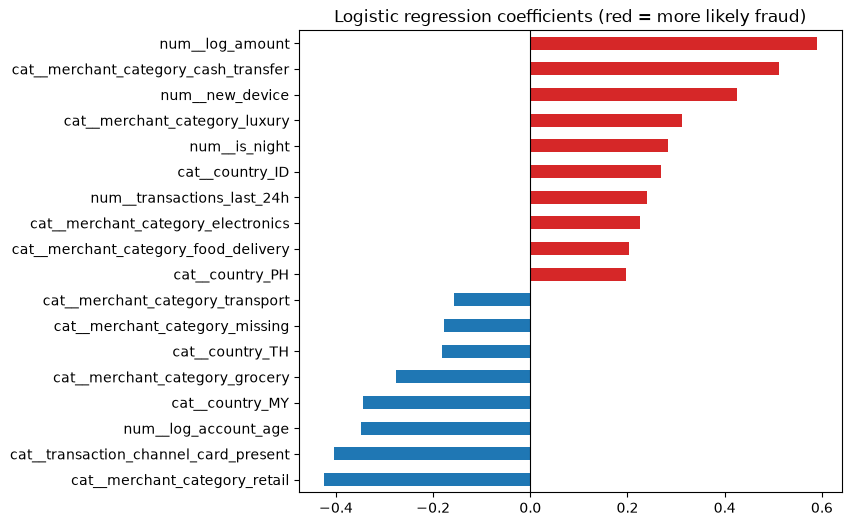

In [14]:
oof_final, fold_ap_final = run_cv(lambda: make_logreg(C=BEST_C))
print("final model PR-AUC:", round(average_precision_score(y, oof_final), 4), "| per fold:", fold_ap_final.round(3))

# what does the model look at? (coefficients on standardised features)
coef_model = make_logreg(C=BEST_C).fit(X, y)
names = coef_model[1].get_feature_names_out()
coefs = pd.Series(coef_model[-1].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(10)])

top.plot.barh(figsize=(7, 6), color=["tab:blue" if v < 0 else "tab:red" for v in top])
plt.title("Logistic regression coefficients (red = more likely fraud)")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

## 6. Threshold tuning

The model gives a probability, but F1 and recall need a yes/no. The default 0.5 is far too high for a 1.8% problem.
We pick the threshold that **maximises F1 on the out-of-fold predictions**, so it was chosen on data the model didn't train on.

best threshold: 0.143  F1=0.302  recall=0.255  precision=0.370


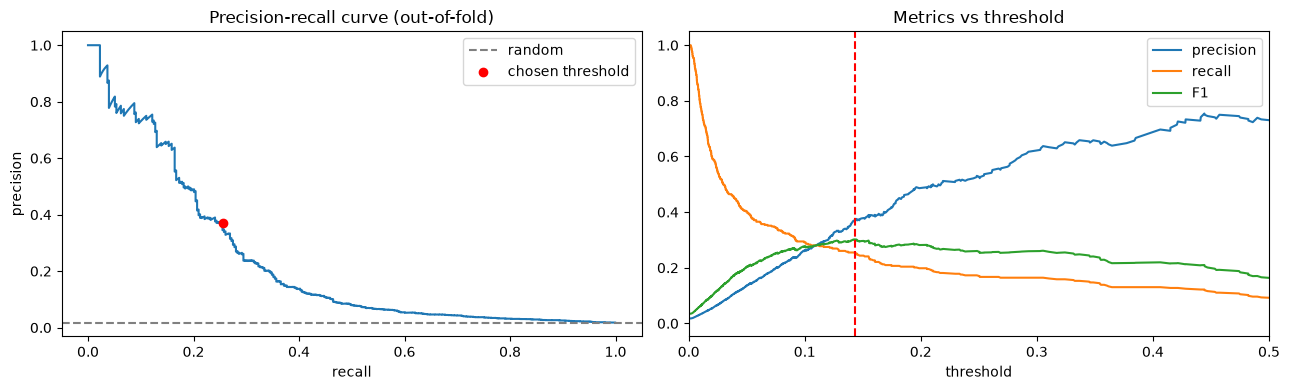

In [15]:
precision, recall, thresholds = precision_recall_curve(y, oof_final)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_i = f1[:-1].argmax()
THRESHOLD = float(thresholds[best_i])
print(f"best threshold: {THRESHOLD:.3f}  F1={f1[best_i]:.3f}  recall={recall[best_i]:.3f}  precision={precision[best_i]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(recall, precision)
axes[0].axhline(y.mean(), color="gray", linestyle="--", label="random")
axes[0].scatter(recall[best_i], precision[best_i], color="red", zorder=3, label="chosen threshold")
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title("Precision-recall curve (out-of-fold)")
axes[0].legend()

axes[1].plot(thresholds, precision[:-1], label="precision")
axes[1].plot(thresholds, recall[:-1], label="recall")
axes[1].plot(thresholds, f1[:-1], label="F1")
axes[1].axvline(THRESHOLD, color="red", linestyle="--")
axes[1].set_xlim(0, 0.5)
axes[1].set_xlabel("threshold")
axes[1].set_title("Metrics vs threshold")
axes[1].legend()

plt.tight_layout()
plt.show()

In [16]:
# trade-off table: what you get at different thresholds
rows = []
for t in [0.02, 0.05, 0.1, THRESHOLD, 0.3, 0.5]:
    pred = (oof_final >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    rows.append({"threshold": round(t, 3), "frauds caught": tp, "frauds missed": fn,
                 "false alarms": fp, "recall": tp / (tp + fn), "precision": tp / max(tp + fp, 1),
                 "F1": f1_score(y, pred), "alerts per 1000 txns": 1000 * (tp + fp) / len(y)})
pd.DataFrame(rows).round(3)

,threshold,frauds caught,frauds missed,false alarms,recall,precision,F1,alerts per 1000 txns
0,0.020,212,141,3707,0.601,0.054,0.099,195.95
1,0.050,142,211,898,0.402,0.137,0.204,52.00
2,0.100,103,250,289,0.292,0.263,0.277,19.60
3,0.143,90,263,153,0.255,0.370,0.302,12.15
4,0.300,58,295,35,0.164,0.624,0.260,4.65
5,0.500,32,321,12,0.091,0.727,0.161,2.20


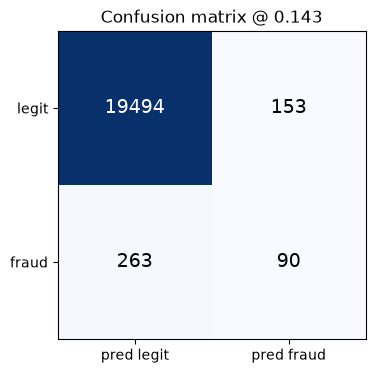

In [17]:
pred_final = (oof_final >= THRESHOLD).astype(int)
cm = confusion_matrix(y, pred_final)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1])
ax.set_xticklabels(["pred legit", "pred fraud"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["legit", "fraud"])
ax.set_title(f"Confusion matrix @ {THRESHOLD:.3f}")
plt.show()

**Trade-off.** Lowering the threshold catches more fraud but flags many more legitimate customers.
- The F1-best threshold is a balanced choice that keeps false alarms low.
- If the bank cares more about catching fraud (a missed fraud costs much more than a customer verification), a lower threshold like 0.05 raises recall from 25% to 40%. The price: false alarms go from 153 to 898, about 6 per fraud caught. That's acceptable only if an alert is a cheap step-up check (OTP), not a blocked card.

The table lets the business pick a point on that curve. We submit the F1-best threshold because F1 is the scored metric.

## 7. Error analysis

In [18]:
err = train.copy()
err["prob"] = oof_final
err["outcome"] = np.select(
    [(y == 1) & (pred_final == 1), (y == 1) & (pred_final == 0), (y == 0) & (pred_final == 1)],
    ["TP (caught)", "FN (missed fraud)", "FP (false alarm)"],
    default="TN",
)

summary_cols = ["transaction_amount", "spend_last_24h", "account_age", "transactions_last_1h", "new_device", "prob"]
display(err.groupby("outcome")[summary_cols].median().round(2))
display(err.groupby("outcome").size().rename("count"))

,transaction_amount,spend_last_24h,account_age,transactions_last_1h,new_device,prob
outcome,,,,,,
FN (missed fraud),184.44,399.20,607.0,1.0,0.0,0.02
FP (false alarm),456.37,1571.92,132.0,4.0,1.0,0.19
TN,73.93,212.43,799.0,1.0,0.0,0.01
TP (caught),651.74,2091.82,56.0,4.0,1.0,0.41


outcome
FN (missed fraud)      263
FP (false alarm)       153
TN                   19494
TP (caught)             90
Name: count, dtype: int64

In [19]:
# where do missed frauds come from?
frauds = err[err[LABEL] == 1]
for col in ["merchant_category", "transaction_channel"]:
    tab = pd.crosstab(frauds[col].fillna("missing"), frauds["outcome"])
    tab["recall"] = (tab.get("TP (caught)", 0) / tab.sum(axis=1)).round(2)
    display(tab.sort_values("recall"))

outcome,FN (missed fraud),TP (caught),recall
merchant_category,,,
entertainment,14,0,0.00
grocery,27,0,0.00
retail,25,0,0.00
utilities,19,0,0.00
transport,19,2,0.10
travel,22,4,0.15
gaming,15,6,0.29
food_delivery,26,12,0.32
luxury,21,10,0.32


outcome,FN (missed fraud),TP (caught),recall
transaction_channel,,,
missing,4,0,0.00
card_present,70,3,0.04
mobile_app,77,10,0.11
ecommerce,83,49,0.37
bank_transfer,29,28,0.49


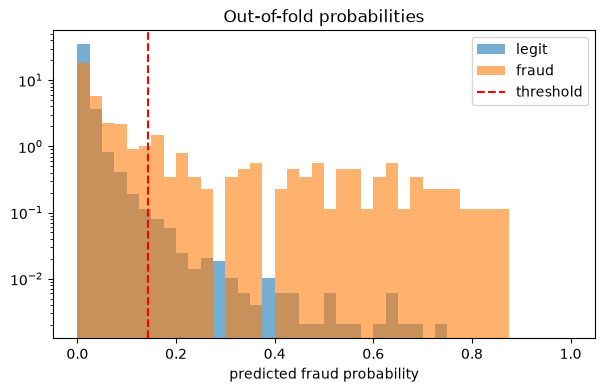

In [20]:
# probability distribution for fraud vs legit
bins = np.linspace(0, 1, 41)
plt.figure(figsize=(7, 4))
plt.hist(err.loc[y == 0, "prob"], bins=bins, alpha=0.6, density=True, label="legit")
plt.hist(err.loc[y == 1, "prob"], bins=bins, alpha=0.6, density=True, label="fraud")
plt.axvline(THRESHOLD, color="red", linestyle="--", label="threshold")
plt.yscale("log")
plt.xlabel("predicted fraud probability")
plt.legend()
plt.title("Out-of-fold probabilities")
plt.show()

**Error analysis findings**
- **Caught frauds** are the "textbook" account-takeover pattern: very new account (median 56 days), new device, large amount (median ~650), several transactions in the last hour.
- **Missed frauds** look like normal customers: older accounts (~600 days), known device, moderate amounts. Fraud in grocery, retail, entertainment and utilities is never caught, and card-present fraud almost never (4% recall). These features can't separate them from legit transactions, so catching them needs more data (customer history, IP, merchant reputation). A threshold tweak won't fix it.
- **False alarms** look like the caught frauds (new account, new device, big spend): legitimate new customers making large purchases. That's the cost of a model that flags new-account risk.
- Most frauds get a low probability (see histogram), so recall is capped. The data separates roughly a quarter to a third of the frauds well.

## 8. Train on all data, predict test, save files

In [21]:
final_model = make_logreg(C=BEST_C).fit(X, y)

test_prob = final_model.predict_proba(test)[:, 1]
test_label = (test_prob >= THRESHOLD).astype(int)

# hard 0/1 labels (for F1 / recall)
submission = pd.DataFrame({"id": test["id"], LABEL: test_label})
submission.to_csv("submission.csv", index=False)

# probabilities (for PR-AUC), in case the portal wants probabilities instead
pd.DataFrame({"id": test["id"], LABEL: test_prob.round(6)}).to_csv("submission_proba.csv", index=False)

# save pipeline + threshold together. cloudpickle stores add_features by value,
# so model.pkl loads in a fresh notebook without redefining the function.
with open("model.pkl", "wb") as f:
    cloudpickle.dump({"pipeline": final_model, "threshold": THRESHOLD}, f)

print(f"test rows: {len(submission)}, predicted fraud: {test_label.sum()} ({100 * test_label.mean():.2f}%)")
print(f"train fraud rate: {100 * y.mean():.2f}%")
submission.head()

test rows: 12000, predicted fraud: 270 (2.25%)
train fraud rate: 1.76%


,id,fraud
0,FR021005,0
1,FR030078,0
2,FR020717,0
3,FR026657,0
4,FR023775,0


In [22]:
# sanity check: reload with plain pickle and reproduce the predictions on the raw csv
import pickle

with open("model.pkl", "rb") as f:
    saved = pickle.load(f)
raw_test = pd.read_csv(DATA_DIR / "Track 2 Testing Dataset.csv")
reloaded_label = (saved["pipeline"].predict_proba(raw_test)[:, 1] >= saved["threshold"]).astype(int)

assert (reloaded_label == submission[LABEL].values).all()
assert len(submission) == len(test) and submission["id"].is_unique
print("all checks passed")

all checks passed


## Summary

| | |
|---|---|
| Model | Logistic regression on log-scaled features plus one-hot categories |
| Why not a bigger model | Random forest and gradient boosting were no better in CV. The signal is additive, and with 353 frauds the simple model is more stable and easy to explain |
| Imbalance handling | No resampling. Tuned decision threshold on out-of-fold predictions, since class weights didn't improve PR-AUC |
| Validation | Stratified 5-fold, out-of-fold PR-AUC, F1, recall |
| Files | `submission.csv` (0/1), `submission_proba.csv` (probabilities), `model.pkl` (pipeline + threshold), `requirements.txt` |

**Limitations:** many frauds look exactly like normal transactions in these features, so recall is capped. We have no customer id, so no per-customer history. Fraud patterns drift over time, so the model and threshold need regular retraining.